# Bézier fitting on Lift: piecewise cubic curves on R³ × SO(3)

**Who this is for:** you have read `lift_diagnostics_baseline.ipynb`, Parts 5 and 6. You know the fitting target (the commanded poses of `low_dim_abs_q0start.hdf5`), the close command $s$, and the pass rule of section 4.6.

**What this notebook does:** it encodes each commanded trajectory as a piecewise cubic geodesic Bézier curve on $\mathbb R^3\times SO(3)$, and tests whether the curves reproduce the Lift task. The method is in `docs/manifold_bezier_control_point_extraction_plan.md`. The code is in `bezier_rfm/fitting/`.

**Outline**

- **Part 1 (H22).** The decoder: is it correct? Unit checks on a synthetic curve.
- **Part 2 (H23).** The fit on `demo_0`: does it converge?
- **Part 3 (H24).** All 200 demonstrations: do the fits reproduce the task?

**Before you run:** JAX runs on the CPU in float64. The first cell sets this, so run it before any other cell.

In [1]:
import os

# Must be set before JAX starts. Small fits run faster on the CPU than with GPU call overhead.
os.environ["JAX_PLATFORMS"] = "cpu"

import jax

jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.transform import Rotation

from bezier_rfm.fitting import so3
from bezier_rfm.fitting.bezier import Controls, decode, knots, segment_controls, segment_point, velocity
from bezier_rfm.fitting.fit import fit, jacobian, residuals, split_free

COLORS = {"curve": "#2a78d6", "naive": "#eb6834", "knot": "#555555", "close": "#d03b3b", "sample": "#1baf7a"}
CHECKS = {}


def record(name, value, limit):
    """Store one check result and print it.

    Args:
        name (str): Check name.
        value (float): Measured value.
        limit (float): Largest value that passes.

    Returns:
        None: Nothing.
    """
    CHECKS[name] = (float(value), limit, bool(value <= limit))
    print(f"{name}: {value:.2e} (limit {limit:.0e}) {'pass' if value <= limit else 'FAIL'}")


print(jax.devices(), "x64:", jax.config.jax_enable_x64)

[CpuDevice(id=0)] x64: True


---
# Part 1. The decoder (H22)

**Hypothesis H22.** The $\mathbb R^3\times SO(3)$ decoder is correct: it passes through its knots, it keeps $q_0$ and $q_K$ fixed, and its velocity in seconds is continuous at every knot, including the close-command knot where the two segment durations differ.

The decoder is section 1.3 of the plan. At knot $k+1$ the backward control is

$$P_{k,2}=\exp_{q_{k+1}}\!\big(-\rho_{k+1}\log_{q_{k+1}}H_{k+1}\big),\qquad \rho_{k+1}=h_k/h_{k+1}.$$

$\rho\neq1$ only at the close-command knot. The checks, agreed before the run:

| # | Check | Pass if |
| --- | --- | --- |
| 1 | $\operatorname{Log}(\operatorname{Exp}(\omega))=\omega$ for angles 0 to 3 rad; Jacobians finite and correct at the identity | error ≤ 1e-12 |
| 2 | `decode` returns $q_k$ at every knot time $\tau_k$ (includes $q_0$ at 0 and $q_K$ at the end) | error ≤ 1e-12 |
| 3 | one-sided velocities in seconds agree at every interior knot; a central finite difference of `decode` agrees with them | ≤ 1e-9; ≤ 1e-6 at $\varepsilon=10^{-8}$ s (revised, see 1.4) |
| 4 | the end velocities of each segment equal $\pm\frac{3}{h_k}\log(\cdot)$ | ≤ 1e-10 |
| 5 | residual Jacobian (`jax.jacfwd`) vs central finite differences, also at coincident poses | relative ≤ 1e-6 |
| 6 | a fit from a perturbed start recovers samples of a known curve; $q_0$ and $q_K$ do not move | RMS ≤ 1e-9 m and rad; exactly 0 |

All checks use one synthetic curve with $(K_1,K_2)=(3,2)$, $T_{pre}=1.35$ s and $T_{post}=0.30$ s. So $h_1=0.45$ s, $h_2=0.15$ s, and the duration ratio at the close-command knot is 3. A ratio of 1 would not test the new part of the decoder.

## 1.1 The synthetic curve

The knot poses lie near a line from the start to the end, with random rotations of about 0.5 rad. The handles are random poses near their knots. These values are not Lift data. They only have to give a curve with clear turns and speed changes.

In [2]:
rng = np.random.default_rng(0)
K1, K2 = 3, 2
K = K1 + K2
T_PRE, T_POST = 1.35, 0.30

q_pos = np.linspace([0.0, 0.0, 1.0], [-0.1, 0.05, 0.85], K + 1) + 0.02 * rng.normal(size=(K + 1, 3))
q_rot = Rotation.from_rotvec(0.3 * rng.normal(size=(K + 1, 3))).as_matrix()
h_pos = q_pos + 0.03 * rng.normal(size=(K + 1, 3))
h_rot = q_rot @ Rotation.from_rotvec(0.15 * rng.normal(size=(K + 1, 3))).as_matrix()
TRUE = Controls(q_pos, q_rot, h_pos, h_rot)

H, TAU = (np.asarray(a) for a in knots(T_PRE, T_POST, K1, K2))
print("segment durations h (s):", H)
print("knot times tau (s):     ", TAU)
print("ratio rho at the close-command knot:", H[K1 - 1] / H[K1])

segment durations h (s): [0.45 0.45 0.45 0.15 0.15]
knot times tau (s):      [0.   0.45 0.9  1.35 1.5  1.65]
ratio rho at the close-command knot: 3.0


## 1.2 Check 1: Exp and Log on SO(3)

`so3.exp` and `so3.log` use Taylor series near angle 0, so that values and autodiff Jacobians stay finite there. The check uses 200 random axes with angles from 0 to 3 rad, with several angles near 0. It also compares `so3.exp` with SciPy, and checks two Jacobians:
- $\partial\operatorname{Exp}/\partial\omega$ at $\omega=0$ must be the three generators $\hat e_i$;
- $\partial\operatorname{Log}(\operatorname{Exp}(\omega))/\partial\omega$ must be the identity matrix at $\omega=0$, $10^{-9}$ and $10^{-5}$ (both series branches and the switch between them).

In [3]:
axes = rng.normal(size=(200, 3))
axes /= np.linalg.norm(axes, axis=1, keepdims=True)
angles = np.r_[0.0, 1e-12, 1e-8, 1e-5, 1e-4, np.linspace(1e-3, 3.0, 195)]
w = axes * angles[:, None]

record("1a |Log(Exp(w)) - w|", np.abs(np.asarray(jax.vmap(lambda v: so3.log(so3.exp(v)))(w)) - w).max(), 1e-12)
record("1b |Exp(w) - SciPy|", np.abs(np.asarray(jax.vmap(so3.exp)(w)) - Rotation.from_rotvec(w).as_matrix()).max(), 1e-12)

generators = np.stack([np.asarray(so3.hat(e)) for e in np.eye(3)], axis=-1)
record("1c |dExp/dw at 0 - generators|", np.abs(np.asarray(jax.jacfwd(so3.exp)(jnp.zeros(3))) - generators).max(), 1e-12)
chain = [np.asarray(jax.jacfwd(lambda v: so3.log(so3.exp(v)))(a * axes[0])) for a in (0.0, 1e-9, 1e-5)]
record("1d |dLog(Exp(w))/dw - I| near 0", max(np.abs(j - np.eye(3)).max() for j in chain), 1e-12)

1a |Log(Exp(w)) - w|: 6.66e-16 (limit 1e-12) pass
1b |Exp(w) - SciPy|: 5.00e-16 (limit 1e-12) pass


1c |dExp/dw at 0 - generators|: 0.00e+00 (limit 1e-12) pass


1d |dLog(Exp(w))/dw - I| near 0: 1.68e-22 (limit 1e-12) pass


## 1.3 Check 2: the curve passes through its knots

`decode` at the six knot times must return the six knot poses $q_0,\ldots,q_5$. This includes $t=0$ (the fixed start), $t=T_{pre}$ (the close-command knot) and $t=T_{pre}+T_{post}$ (the fixed end).

In [4]:
p_k, r_k = decode(TRUE, T_PRE, T_POST, K1, K2, jnp.asarray(TAU))
record("2 |decode(tau_k) - q_k|", max(np.abs(np.asarray(p_k) - q_pos).max(), np.abs(np.asarray(r_k) - q_rot).max()), 1e-12)

2 |decode(tau_k) - q_k|: 8.05e-16 (limit 1e-12) pass


## 1.4 Check 3: C1 in seconds at every knot

For each interior knot, `seg_velocity` differentiates the segment before it at $u=1$ and the segment after it at $u=0$ with `jax.jacfwd`, and divides by the segment duration. The result is the linear velocity (m/s) and the body-frame angular velocity (rad/s). The two one-sided velocities must agree.

As an independent check, a central finite difference of the full `decode` across the knot must agree with them. Its step is $\varepsilon=10^{-8}$ s. At a knot the acceleration can jump, so the error of this difference is about $\varepsilon/4$ times the jump.

**Revised criterion (after the first run, user decision).** The first run used $\varepsilon=10^{-7}$ s and gave 3.9e-6, above the limit of 1e-6. A scan of $\varepsilon$ from 1e-5 to 1e-8 (run once in a scratch script, not in this notebook) showed that the difference falls by a factor of 10 per decade of $\varepsilon$ at every knot. A real velocity mismatch would not shrink with $\varepsilon$. So the difference is truncation error at an acceleration jump, which a $C^1$ curve may have. The rule is now: the difference falls linearly with $\varepsilon$ (shown by the scan), and it is at most 1e-6 at $\varepsilon=10^{-8}$ s. Rounding error at this step is about $10^{-16}/10^{-8}=10^{-8}$, well below the limit.

As a **negative control**, the same comparison is made for the plain reflection ($\rho=1$ everywhere). It must show a velocity jump at the close-command knot only. This shows that check 3 can detect a missing duration ratio.

In [5]:
P_POS, P_ROT = segment_controls(TRUE, jnp.asarray(H))
NAIVE_POS, NAIVE_ROT = segment_controls(TRUE, jnp.ones(K))  # rho = 1 at every knot


def seg_velocity(pos, rot, k, u):
    """Return [linear, angular] velocity in seconds of segment k at local parameter u.

    Args:
        pos (jnp.ndarray): Control positions, shape (K, 4, 3).
        rot (jnp.ndarray): Control rotations, shape (K, 4, 3, 3).
        k (int): Segment index.
        u (float): Local parameter.

    Returns:
        np.ndarray: Velocity, shape (6,).
    """
    f = lambda x: segment_point(pos[k], rot[k], x)
    (_, r), (dp, dr) = f(u), jax.jacfwd(f)(u)
    return np.r_[dp, so3.vee(r.T @ dr)] / H[k]


EPS = 1e-8
c1, fd, naive = [], [], []
print("knot  tau (s)  |left - right|  |FD - left|  naive |left - right|")
for k in range(1, K):
    left, right = seg_velocity(P_POS, P_ROT, k - 1, 1.0), seg_velocity(P_POS, P_ROT, k, 0.0)
    (pa, pb), (ra, rb) = (np.asarray(a) for a in decode(TRUE, T_PRE, T_POST, K1, K2, jnp.array([TAU[k] - EPS, TAU[k] + EPS])))
    diff = np.r_[(pb - pa) / (2 * EPS), so3.log(ra.T @ rb) / (2 * EPS)]
    c1.append(np.abs(left - right).max())
    fd.append(np.abs(diff - left).max())
    naive.append(np.abs(seg_velocity(NAIVE_POS, NAIVE_ROT, k - 1, 1.0) - seg_velocity(NAIVE_POS, NAIVE_ROT, k, 0.0)).max())
    print(f"{k:4d}  {TAU[k]:6.2f}   {c1[-1]:.1e}       {fd[-1]:.1e}      {naive[-1]:.1e}{'   <- close-command knot' if k == K1 else ''}")
record("3a |left - right velocity| at interior knots", max(c1), 1e-9)
record("3b |central FD - one-sided velocity|, eps = 1e-8", max(fd), 1e-6)

knot  tau (s)  |left - right|  |FD - left|  naive |left - right|


   1    0.45   2.2e-16       2.8e-08      2.2e-16


   2    0.90   1.6e-15       6.2e-08      1.6e-15


   3    1.35   8.9e-16       1.8e-07      9.9e-01   <- close-command knot


   4    1.50   4.4e-15       4.0e-07      4.4e-15
3a |left - right velocity| at interior knots: 4.44e-15 (limit 1e-09) pass
3b |central FD - one-sided velocity|, eps = 1e-8: 3.97e-07 (limit 1e-06) pass


## 1.5 Check 4: segment end velocities

For a cubic geodesic Bézier segment, the velocity at $u=0$ is $\frac{3}{h_k}\log_{P_{k,0}}(P_{k,1})$ and at $u=1$ it is $-\frac{3}{h_k}\log_{P_{k,3}}(P_{k,2})$, in seconds. The check compares these formulas with the autodiff velocity of every segment.

In [6]:
def log_pose(pos_a, rot_a, pos_b, rot_b):
    """Return log_a(b) = [p_b - p_a, Log(R_a^T R_b)].

    Args:
        pos_a (jnp.ndarray): Position of a, shape (3,).
        rot_a (jnp.ndarray): Rotation of a, shape (3, 3).
        pos_b (jnp.ndarray): Position of b, shape (3,).
        rot_b (jnp.ndarray): Rotation of b, shape (3, 3).

    Returns:
        np.ndarray: Tangent vector, shape (6,).
    """
    return np.r_[pos_b - pos_a, so3.log(rot_a.T @ rot_b)]


err = 0.0
for k in range(K):
    start = 3 / H[k] * log_pose(P_POS[k, 0], P_ROT[k, 0], P_POS[k, 1], P_ROT[k, 1])
    end = -3 / H[k] * log_pose(P_POS[k, 3], P_ROT[k, 3], P_POS[k, 2], P_ROT[k, 2])
    err = max(err, np.abs(seg_velocity(P_POS, P_ROT, k, 0.0) - start).max(), np.abs(seg_velocity(P_POS, P_ROT, k, 1.0) - end).max())
record("4 |autodiff - analytic end velocity|", err, 1e-10)

4 |autodiff - analytic end velocity|: 4.44e-15 (limit 1e-10) pass


## 1.6 Check 5: residual Jacobian

The fit uses `jacobian` (`jax.jacfwd` of the residual) in SciPy. The check compares $J\,d$ with a central finite difference along 10 random unit directions $d$, in three configurations:
- **coincident:** the charts sit at the true controls, so every residual is exactly 0 and every `Log` is evaluated at the identity;
- **perturbed:** the charts sit at perturbed controls (1 cm and 0.05 rad);
- **perturbed, off-centre:** as above, but at a nonzero chart coordinate.

The samples are at $t_i=0.05\,i$ s, as for Lift actions: $N=34$ here.

In [7]:
N = int(round((T_PRE + T_POST) / 0.05)) + 1
T = 0.05 * np.arange(N)
P_T, R_T = (np.asarray(a) for a in decode(TRUE, T_PRE, T_POST, K1, K2, jnp.asarray(T)))
ENDS = (np.stack([q_pos[0], q_pos[-1]]), np.stack([q_rot[0], q_rot[-1]]))
DATA = (*ENDS, T_PRE, T_POST, T[1:-1], P_T[1:-1], R_T[1:-1], 1 / np.sqrt(N))


def perturb(c, pos, ang):
    """Move the free controls by random offsets; q_0 and q_K stay.

    Args:
        c (Controls): Controls.
        pos (float): Position offset scale, m.
        ang (float): Rotation offset scale, rad.

    Returns:
        Controls: Perturbed controls.
    """
    n = len(c.q_pos)
    dq, dh = pos * rng.normal(size=(n, 3)), pos * rng.normal(size=(n, 3))
    rq, rh = (Rotation.from_rotvec(ang * rng.normal(size=(n, 3))).as_matrix() for _ in range(2))
    dq[[0, -1]], rq[[0, -1]] = 0.0, np.eye(3)
    return Controls(c.q_pos + dq, c.q_rot @ rq, c.h_pos + dh, c.h_rot @ rh)


C0 = perturb(TRUE, 0.01, 0.05)


def jacobian_error(c, x):
    """Return the largest relative error of J d vs a central finite difference over 10 directions.

    Args:
        c (Controls): Chart anchors.
        x (np.ndarray): Chart coordinates, shape (12K,).

    Returns:
        float: Largest relative error.
    """
    anchors = split_free(c)
    j = np.asarray(jacobian(x, *anchors, *DATA, k1=K1, k2=K2))
    res = lambda y: np.asarray(residuals(y, *anchors, *DATA, k1=K1, k2=K2))
    worst = 0.0
    for _ in range(10):
        d = rng.normal(size=x.size)
        d /= np.linalg.norm(d)
        fd = (res(x + 1e-6 * d) - res(x - 1e-6 * d)) / 2e-6
        worst = max(worst, np.linalg.norm(fd - j @ d) / np.linalg.norm(j @ d))
    return worst


zero = np.zeros(12 * K)
print("residual norm at the true controls:", np.linalg.norm(np.asarray(residuals(zero, *split_free(TRUE), *DATA, k1=K1, k2=K2))))
errors = {"coincident": jacobian_error(TRUE, zero), "perturbed": jacobian_error(C0, zero), "perturbed, off-centre": jacobian_error(C0, 0.01 * rng.normal(size=12 * K))}
for name, value in errors.items():
    print(f"  {name}: {value:.1e}")
record("5 relative |J d - FD|", max(errors.values()), 1e-6)

residual norm at the true controls: 7.117366825420465e-17


  coincident: 2.9e-10
  perturbed: 2.6e-10
  perturbed, off-centre: 2.0e-10
5 relative |J d - FD|: 2.86e-10 (limit 1e-06) pass


## 1.7 Check 6: synthetic recovery

`fit` starts from the perturbed controls `C0` and fits the 34 samples of the true curve. The data are exact, so the residual can reach 0. The fit runs twice:
- with the plan's TRF settings (`gtol` = 1e-8), which the real fits will use;
- with tight tolerances (`gtol`, `ftol`, `xtol` = 1e-15), to see whether the residual reaches round-off. The pass limit applies to this run.

The fitted $q_0$ and $q_K$ must equal the true ones exactly: the decoder inserts them, and they have no variables.

In [8]:
def rms(c):
    """Return the RMS position (m) and rotation (rad) residual of controls over all samples.

    Args:
        c (Controls): Controls.

    Returns:
        tuple: RMS position and rotation residual.
    """
    p, r = (np.asarray(a) for a in decode(c, T_PRE, T_POST, K1, K2, jnp.asarray(T)))
    rot = np.asarray(jax.vmap(so3.log)(np.swapaxes(r, 1, 2) @ R_T))
    return np.sqrt(np.mean(np.sum((p - P_T) ** 2, axis=1))), np.sqrt(np.mean(np.sum(rot**2, axis=1)))


print(f"start: RMS {rms(C0)[0]:.1e} m, {rms(C0)[1]:.1e} rad")
for name, trf in (("plan settings", None), ("tight tolerances", {"gtol": 1e-15, "ftol": 1e-15, "xtol": 1e-15})):
    fitted, diag = fit(C0, T_PRE, T_POST, K1, K2, T[1:-1], P_T[1:-1], R_T[1:-1], N, trf=trf)
    e_pos, e_rot = rms(fitted)
    nfev = sum(h["nfev"] for h in diag["history"][1:])
    print(f"{name}: RMS {e_pos:.1e} m, {e_rot:.1e} rad; status {diag['status']}, charts {diag['charts']}, active bounds {diag['active']}, evaluations {nfev}")
record("6a RMS residual, tight tolerances", max(e_pos, e_rot), 1e-9)
ends_moved = max(np.abs(fitted.q_pos[[0, -1]] - q_pos[[0, -1]]).max(), np.abs(fitted.q_rot[[0, -1]] - q_rot[[0, -1]]).max())
record("6b |q_0, q_K fitted - true|", ends_moved, 0.0)
FITTED = fitted

start: RMS 1.3e-02 m, 1.0e-01 rad


plan settings: RMS 8.3e-17 m, 7.6e-08 rad; status 1, charts 1, active bounds 0, evaluations 5


tight tolerances: RMS 7.1e-17 m, 8.5e-17 rad; status 1, charts 1, active bounds 0, evaluations 7
6a RMS residual, tight tolerances: 8.51e-17 (limit 1e-09) pass
6b |q_0, q_K fitted - true|: 0.00e+00 (limit 0e+00) pass


## 1.8 Visual: the synthetic curve and its speed

Four panels over time in seconds:
- position $x, y, z$, with the samples at 0.05 s as dots;
- rotation vector of $R_0^\top R(t)$, the rotation relative to the start;
- linear speed $\|v\|$ and angular speed $\|\omega\|$.

Grey dotted lines are knots; the red line is the close-command knot. In the speed panels, the orange dashed line is the negative control ($\rho=1$). The blue curve must be continuous at every knot. The orange curve must jump at the close-command knot only. Elsewhere the two curves are the same.

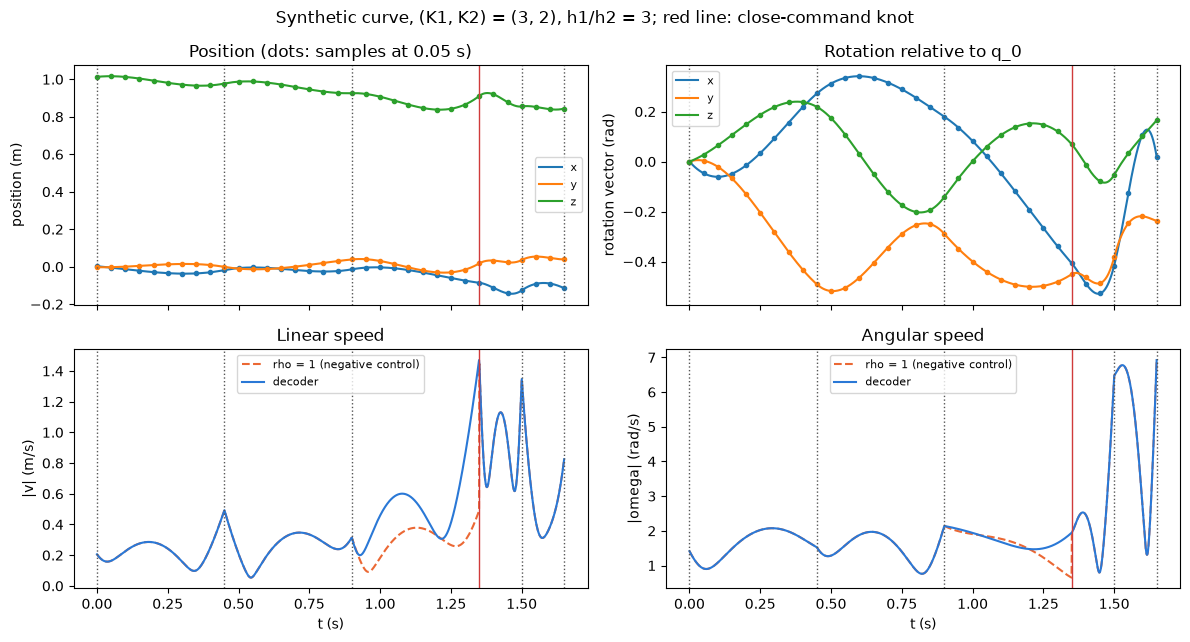

In [9]:
TT = np.linspace(0.0, T_PRE + T_POST, 1500)
p_tt, r_tt = (np.asarray(a) for a in decode(TRUE, T_PRE, T_POST, K1, K2, jnp.asarray(TT)))
v_tt, w_tt = (np.asarray(a) for a in velocity(TRUE, T_PRE, T_POST, K1, K2, jnp.asarray(TT)))
rv_tt = np.asarray(jax.vmap(so3.log)(q_rot[0].T @ r_tt))
rv_t = np.asarray(jax.vmap(so3.log)(q_rot[0].T @ R_T))

# The rho = 1 curve: same segment lookup as decode, with the naive controls.
seg = np.clip(np.searchsorted(TAU, TT, side="right") - 1, 0, K - 1)
u = (TT - TAU[seg]) / H[seg]
naive_speed = np.array([np.linalg.norm(seg_velocity(NAIVE_POS, NAIVE_ROT, k, x)[:3]) for k, x in zip(seg, u)])
naive_omega = np.array([np.linalg.norm(seg_velocity(NAIVE_POS, NAIVE_ROT, k, x)[3:]) for k, x in zip(seg, u)])

fig, axs = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for i, axis in enumerate("xyz"):
    axs[0, 0].plot(TT, p_tt[:, i], label=axis)
    axs[0, 0].plot(T, P_T[:, i], "o", ms=3, color=axs[0, 0].lines[-1].get_color())
    axs[0, 1].plot(TT, rv_tt[:, i], label=axis)
    axs[0, 1].plot(T, rv_t[:, i], "o", ms=3, color=axs[0, 1].lines[-1].get_color())
axs[1, 0].plot(TT, naive_speed, "--", color=COLORS["naive"], label="rho = 1 (negative control)")
axs[1, 0].plot(TT, np.linalg.norm(v_tt, axis=1), color=COLORS["curve"], label="decoder")
axs[1, 1].plot(TT, naive_omega, "--", color=COLORS["naive"], label="rho = 1 (negative control)")
axs[1, 1].plot(TT, np.linalg.norm(w_tt, axis=1), color=COLORS["curve"], label="decoder")
for ax in axs.flat:
    for k, tk in enumerate(TAU):
        ax.axvline(tk, color=COLORS["close"] if k == K1 else COLORS["knot"], ls="-" if k == K1 else ":", lw=1)
axs[0, 0].set(ylabel="position (m)", title="Position (dots: samples at 0.05 s)")
axs[0, 1].set(ylabel="rotation vector (rad)", title="Rotation relative to q_0")
axs[1, 0].set(xlabel="t (s)", ylabel="|v| (m/s)", title="Linear speed")
axs[1, 1].set(xlabel="t (s)", ylabel="|omega| (rad/s)", title="Angular speed")
for ax in axs.flat:
    ax.legend(fontsize=8)
fig.suptitle("Synthetic curve, (K1, K2) = (3, 2), h1/h2 = 3; red line: close-command knot")
fig.tight_layout()
plt.show()

## 1.9 Summary of the checks

In [10]:
print(f"{'check':48s} {'value':>9s} {'limit':>7s}  result")
for name, (value, limit, ok) in CHECKS.items():
    print(f"{name:48s} {value:9.1e} {limit:7.0e}  {'pass' if ok else 'FAIL'}")
print(f"\n{sum(ok for *_, ok in CHECKS.values())} of {len(CHECKS)} checks pass")

check                                                value   limit  result
1a |Log(Exp(w)) - w|                               6.7e-16   1e-12  pass
1b |Exp(w) - SciPy|                                5.0e-16   1e-12  pass
1c |dExp/dw at 0 - generators|                     0.0e+00   1e-12  pass
1d |dLog(Exp(w))/dw - I| near 0                    1.7e-22   1e-12  pass
2 |decode(tau_k) - q_k|                            8.0e-16   1e-12  pass
3a |left - right velocity| at interior knots       4.4e-15   1e-09  pass
3b |central FD - one-sided velocity|, eps = 1e-8   4.0e-07   1e-06  pass
4 |autodiff - analytic end velocity|               4.4e-15   1e-10  pass
5 relative |J d - FD|                              2.9e-10   1e-06  pass
6a RMS residual, tight tolerances                  8.5e-17   1e-09  pass
6b |q_0, q_K fitted - true|                        0.0e+00   0e+00  pass

11 of 11 checks pass


## 1.10 Result of H22

**H22 is confirmed, with check 3b revised after the first run (user decision).** All 11 checks pass.

- `Exp` and `Log` agree with each other and with SciPy to about 1e-15. Their Jacobians are exact at the identity, on both sides of the series switch.
- The curve passes through all six knots, including the fixed $q_0$ and $q_K$, to 8e-16.
- The one-sided velocities in seconds agree to 4e-15 at every interior knot, including the close-command knot with $h_1/h_2=3$. The negative control ($\rho=1$) jumps by 0.99 at that knot only. So check 3a can detect a missing ratio.
- The central finite difference agrees with the one-sided velocities to 4.0e-7 at $\varepsilon=10^{-8}$ s (revised check 3b).
- The residual Jacobian agrees with finite differences to 3e-10, also at coincident poses.
- The fit recovers the true curve from a start 1.3 cm and 0.1 rad away: RMS 9e-17 with tight tolerances. With the plan's settings it stops at 8e-17 m and 7.6e-8 rad (`gtol`). $q_0$ and $q_K$ do not move.

**About check 3b.** As first agreed, it used $\varepsilon=10^{-7}$ s and gave 3.9e-6, above the limit of 1e-6. A scan of $\varepsilon$ in a scratch script showed that the difference falls by a factor of 10 per decade of $\varepsilon$, so it is truncation error at an acceleration jump, not a velocity mismatch. The revised rule (section 1.4) uses $\varepsilon=10^{-8}$ s with the same limit.

In the figure, the decoder's linear and angular speeds are continuous at every knot. The $\rho=1$ curve jumps at the close-command knot only, and is the same as the decoder before $\tau_2$ and after $\tau_3$.

---
# Part 2. The fit on demo_0 (H23)

**Hypothesis H23.** The fit converges on `demo_0` with $(K_1,K_2)=(5,2)$: the solver stops for a convergence reason, and the result is a true minimum of the loss.

The fit target is the commanded poses of `low_dim_abs_q0start.hdf5`. The initialization comes from the commands themselves (plan section 2). The criteria, agreed before the run:

| # | Check | Pass if |
| --- | --- | --- |
| 1 | TRF termination | status 1 to 4 (a tolerance), not 0 (`max_nfev`) |
| 2 | objective over chart re-centerings | never increases |
| 3 | rotation bounds at the end | none active |
| 4 | position part vs its closed-form linear least-squares optimum | decoded positions within 1e-9 m |
| 5 | fixed points and close step | $q_0$, $q_K$ equal the commands exactly; $\operatorname{round}(T_{pre}/0.05)=s$ |

**Reported, no limit:** RMS and largest residual in mm and degrees, next to the section 5.6 spline preview with the same total $K=7$, refitted here on the same commands. The comparison is rough: the preview is $C^2$, has free endpoints, and uses normalized time. The fit residual also measures the command jitter (baseline notebook, section 5.6), so a small residual is not the aim.

## 2.1 The commands of demo_0

Action $i$ holds the commanded pose at $t_i=0.05\,i$ s. Action 0 is the start pose. The close command $s$ is the first action with the gripper closed.

In [2]:
from pathlib import Path
import time

import h5py

from bezier_rfm.fitting.fit import initialize, position_lstsq

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
Q0START_PATH = ROOT / "data/robomimic/datasets/lift/ph/low_dim_abs_q0start.hdf5"


def load_commands(name):
    """Read one demonstration's commanded poses and close command from the q0-start file.

    Args:
        name (str): Demonstration name.

    Returns:
        tuple: Positions, shape (N, 3), rotations, shape (N, 3, 3), and close command s (int).
    """
    with h5py.File(Q0START_PATH, "r") as f:
        actions = f[f"data/{name}/actions"][:]
    s = int(np.flatnonzero(np.diff(actions[:, 6]))[0]) + 1
    return actions[:, :3], Rotation.from_rotvec(actions[:, 3:6]).as_matrix(), s


P_CMD, R_CMD, S_CLOSE = load_commands("demo_0")
N0 = len(P_CMD)
T0 = 0.05 * np.arange(N0)
print(f"demo_0: N = {N0} actions, close command s = {S_CLOSE}, T_pre = {0.05 * S_CLOSE:.2f} s, T_post = {0.05 * (N0 - 1 - S_CLOSE):.2f} s")

demo_0: N = 59 actions, close command s = 44, T_pre = 2.20 s, T_post = 0.70 s


## 2.2 Initialization and fit

`initialize` places the knots, interpolates the knot poses from the commands, estimates the velocities by finite differences in seconds, and builds the handles. `fit` then runs TRF with the plan's settings. The knot times are $\tau_k=k\,h_1$ before the close-command knot and $T_{pre}+(k-5)\,h_2$ after it.

In [3]:
K1_D, K2_D = 5, 2
C_INIT, T_PRE_D, T_POST_D = initialize(P_CMD, R_CMD, S_CLOSE, K1_D, K2_D)
H_D, TAU_D = (np.asarray(a) for a in knots(T_PRE_D, T_POST_D, K1_D, K2_D))
print("segment durations h (s):", np.round(H_D, 4))
print("knot times tau (s):     ", np.round(TAU_D, 4))

start = time.perf_counter()
C_FIT, DIAG = fit(C_INIT, T_PRE_D, T_POST_D, K1_D, K2_D, T0[1:-1], P_CMD[1:-1], R_CMD[1:-1], N0)
print(f"fit time {time.perf_counter() - start:.1f} s (includes JIT compilation)")
print(f"{'chart':>5s} {'cost':>12s} {'status':>7s} {'nfev':>5s} {'njev':>5s} {'active':>7s}")
for i, h in enumerate(DIAG["history"]):
    print(f"{i:5d} {h['cost']:12.4e} {h.get('status', ''):>7} {h.get('nfev', ''):>5} {h.get('njev', ''):>5} {h.get('active', ''):>7}")

segment durations h (s): [0.44 0.44 0.44 0.44 0.44 0.35 0.35]
knot times tau (s):      [0.   0.44 0.88 1.32 1.76 2.2  2.55 2.9 ]


fit time 2.2 s (includes JIT compilation)
chart         cost  status  nfev  njev  active
    0   1.1808e-04                            
    1   2.2946e-05       1     4     4       0


## 2.3 Checks and residuals

`errors` returns the position residual (mm) and the rotation residual (degrees) at every action. `position_lstsq` solves the position part alone in closed form, with the fitted rotations. The loss separates (plan section 1.5), so TRF must give the same positions.

In [4]:
from scipy.interpolate import make_lsq_spline


def errors(c, k1, k2, t_pre, t_post, p, r):
    """Return the position (mm) and rotation (deg) residual of controls at every action.

    Args:
        c (Controls): Controls.
        k1 (int): Number of segments before the knot.
        k2 (int): Number of segments after the knot.
        t_pre (float): Duration before the close-command knot, in s.
        t_post (float): Duration after the close-command knot, in s.
        p (np.ndarray): Commanded positions, shape (N, 3).
        r (np.ndarray): Commanded rotations, shape (N, 3, 3).

    Returns:
        np.ndarray: Residuals, shape (N, 2).
    """
    t = 0.05 * np.arange(len(p))
    p_hat, r_hat = (np.asarray(a) for a in decode(c, t_pre, t_post, k1, k2, jnp.asarray(t)))
    rot = Rotation.from_matrix(np.swapaxes(r_hat, 1, 2) @ r).magnitude()
    return np.stack([1000 * np.linalg.norm(p_hat - p, axis=1), np.degrees(rot)], axis=1)


def preview_errors(p, r, k):
    """Return the section 5.6 spline-preview residual, position (mm) and rotation (deg), at every action.

    Args:
        p (np.ndarray): Commanded positions, shape (N, 3).
        r (np.ndarray): Commanded rotations, shape (N, 3, 3).
        k (int): Number of equal segments in normalized time.

    Returns:
        np.ndarray: Residuals, shape (N, 2).
    """
    u = np.arange(len(p)) / (len(p) - 1)
    knot_vec = np.r_[[0.0] * 4, np.linspace(0, 1, k + 1)[1:-1], [1.0] * 4]
    rotvec = Rotation.from_matrix(r[0].T @ r).as_rotvec()
    pos_fit = make_lsq_spline(u, p, knot_vec, k=3)(u)
    rot_fit = r[0] @ Rotation.from_rotvec(make_lsq_spline(u, rotvec, knot_vec, k=3)(u)).as_matrix()
    rot = Rotation.from_matrix(np.swapaxes(rot_fit, 1, 2) @ r).magnitude()
    return np.stack([1000 * np.linalg.norm(pos_fit - p, axis=1), np.degrees(rot)], axis=1)


H23 = {}
H23["1 status"] = DIAG["status"]
costs = [h["cost"] for h in DIAG["history"]]
H23["2 largest cost increase"] = max(np.diff(costs).max(), 0.0)
H23["3 active bounds"] = DIAG["active"]
ls_pos = position_lstsq(C_FIT, T_PRE_D, T_POST_D, K1_D, K2_D, T0[1:-1], P_CMD[1:-1])
qi, hi = np.array([2 * k - 1 for k in range(1, K1_D + K2_D)]), np.r_[0, 2 * np.arange(1, K1_D + K2_D), 2 * (K1_D + K2_D) - 1]
C_LS = C_FIT._replace(q_pos=np.r_[C_FIT.q_pos[:1], ls_pos[qi], C_FIT.q_pos[-1:]], h_pos=ls_pos[hi])
p_fit = np.asarray(decode(C_FIT, T_PRE_D, T_POST_D, K1_D, K2_D, jnp.asarray(T0))[0])
p_ls = np.asarray(decode(C_LS, T_PRE_D, T_POST_D, K1_D, K2_D, jnp.asarray(T0))[0])
H23["4 |decoded positions TRF - lstsq| (m)"] = np.abs(p_fit - p_ls).max()
H23["5 |q_0, q_K - commands|"] = max(np.abs(C_FIT.q_pos[[0, -1]] - P_CMD[[0, -1]]).max(), np.abs(C_FIT.q_rot[[0, -1]] - R_CMD[[0, -1]]).max())
H23["5 round(T_pre / 0.05) - s"] = round(T_PRE_D / 0.05) - S_CLOSE
for name, value in H23.items():
    print(f"{name:42s} {value}")

E_INIT = errors(C_INIT, K1_D, K2_D, T_PRE_D, T_POST_D, P_CMD, R_CMD)
E_FIT = errors(C_FIT, K1_D, K2_D, T_PRE_D, T_POST_D, P_CMD, R_CMD)
E_PREV = preview_errors(P_CMD, R_CMD, K1_D + K2_D)
print(f"\n{'demo_0':24s} {'pos RMS':>9s} {'pos max':>9s} {'rot RMS':>9s} {'rot max':>9s}")
for name, e in (("initialization", E_INIT), ("fit, (5, 2)", E_FIT), ("5.6 preview, K = 7", E_PREV)):
    print(f"{name:24s} {np.sqrt(np.mean(e[:, 0] ** 2)):6.2f} mm {e[:, 0].max():6.2f} mm {np.sqrt(np.mean(e[:, 1] ** 2)):5.2f} deg {e[:, 1].max():5.2f} deg")

1 status                                   1
2 largest cost increase                    0.0
3 active bounds                            0
4 |decoded positions TRF - lstsq| (m)      4.773959005888173e-15
5 |q_0, q_K - commands|                    0.0
5 round(T_pre / 0.05) - s                  0

demo_0                     pos RMS   pos max   rot RMS   rot max
initialization            11.34 mm  26.58 mm  0.59 deg  2.41 deg
fit, (5, 2)                4.69 mm  10.63 mm  0.28 deg  1.68 deg
5.6 preview, K = 7         5.55 mm  13.08 mm  0.36 deg  1.52 deg


## 2.4 Visual: commands, fit, residuals, and speed

Six panels over time in seconds:
- position and rotation (rotation vector of $R_0^\top R$): commands as dots, the fit as lines, the initialization as thin dashed lines;
- residual per action, fit and section 5.6 preview;
- linear and angular speed of the fit. They must be continuous at every knot.

Grey dotted lines are knots; the red line is the close-command knot (the gripper close command, $t=T_{pre}$).

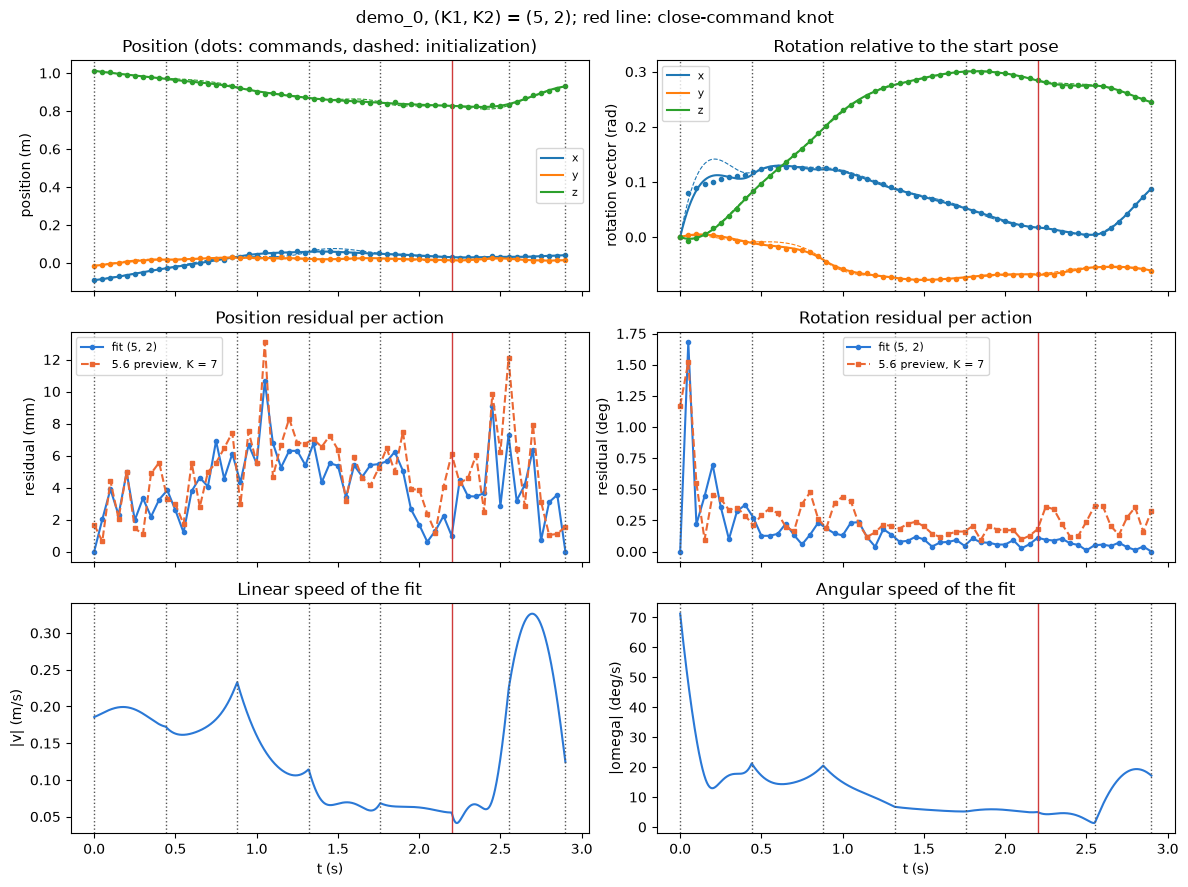

In [5]:
TT0 = np.linspace(0.0, T_PRE_D + T_POST_D, 1200)
p_tt, r_tt = (np.asarray(a) for a in decode(C_FIT, T_PRE_D, T_POST_D, K1_D, K2_D, jnp.asarray(TT0)))
p_in, r_in = (np.asarray(a) for a in decode(C_INIT, T_PRE_D, T_POST_D, K1_D, K2_D, jnp.asarray(TT0)))
v_tt, w_tt = (np.asarray(a) for a in velocity(C_FIT, T_PRE_D, T_POST_D, K1_D, K2_D, jnp.asarray(TT0)))
rv = lambda r: Rotation.from_matrix(R_CMD[0].T @ r).as_rotvec()

fig, axs = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for i, axis in enumerate("xyz"):
    for ax, cmd, fitted, init, scale in ((axs[0, 0], P_CMD[:, i], p_tt[:, i], p_in[:, i], 1.0), (axs[0, 1], rv(R_CMD)[:, i], rv(r_tt)[:, i], rv(r_in)[:, i], 1.0)):
        line = ax.plot(TT0, fitted, label=axis)[0]
        ax.plot(TT0, init, "--", lw=0.8, color=line.get_color())
        ax.plot(T0, cmd, "o", ms=3, color=line.get_color())
for j, unit in enumerate(("mm", "deg")):
    axs[1, j].plot(T0, E_FIT[:, j], "o-", ms=3, color=COLORS["curve"], label="fit (5, 2)")
    axs[1, j].plot(T0, E_PREV[:, j], "s--", ms=3, color=COLORS["naive"], label="5.6 preview, K = 7")
    axs[1, j].set(ylabel=f"residual ({unit})")
axs[2, 0].plot(TT0, np.linalg.norm(v_tt, axis=1), color=COLORS["curve"])
axs[2, 1].plot(TT0, np.degrees(np.linalg.norm(w_tt, axis=1)), color=COLORS["curve"])
for ax in axs.flat:
    for k, tk in enumerate(TAU_D):
        ax.axvline(tk, color=COLORS["close"] if k == K1_D else COLORS["knot"], ls="-" if k == K1_D else ":", lw=1)
axs[0, 0].set(ylabel="position (m)", title="Position (dots: commands, dashed: initialization)")
axs[0, 1].set(ylabel="rotation vector (rad)", title="Rotation relative to the start pose")
axs[1, 0].set(title="Position residual per action")
axs[1, 1].set(title="Rotation residual per action")
axs[2, 0].set(xlabel="t (s)", ylabel="|v| (m/s)", title="Linear speed of the fit")
axs[2, 1].set(xlabel="t (s)", ylabel="|omega| (deg/s)", title="Angular speed of the fit")
for ax in axs[:2].flat:
    ax.legend(fontsize=8)
fig.suptitle("demo_0, (K1, K2) = (5, 2); red line: close-command knot")
fig.tight_layout()
plt.show()

## 2.5 Result of H23

**H23 is confirmed.** All five checks pass on `demo_0` with $(K_1,K_2)=(5,2)$ ($N=59$, $s=44$, $h_1=0.44$ s, $h_2=0.35$ s):
1. TRF stops with status 1 (`gtol`) after 4 evaluations.
2. One chart is enough. The cost falls from 1.18e-4 to 2.29e-5 and never increases.
3. No rotation bound is active at the end.
4. The TRF positions equal the closed-form least-squares positions to 4.8e-15 m.
5. $q_0$ and $q_K$ equal the commands exactly, and $\operatorname{round}(T_{pre}/0.05)=s$.

The fit takes 2.2 s, including JIT compilation.

**Residuals (reported only):**

| demo_0 | pos RMS | pos max | rot RMS | rot max |
| --- | --- | --- | --- | --- |
| initialization | 11.3 mm | 26.6 mm | 0.59° | 2.41° |
| fit, (5, 2) | 4.7 mm | 10.6 mm | 0.28° | 1.68° |
| 5.6 preview, $K=7$ | 5.6 mm | 13.1 mm | 0.36° | 1.52° |

The fit is a little closer to the commands than the preview, with the same number of segments. Both residual curves follow the same command jitter, as section 5.6 of the baseline notebook predicted.

**What the figure shows:**
- The linear and angular speeds are continuous at every knot, including the close-command knot. The corners in the speed curves are acceleration jumps, which a $C^1$ curve may have.
- The largest rotation residual (1.68°) is at action 1. Command 1 is already about 0.08 rad (4.6°) from the start pose: this is the lead of command 0 that the baseline notebook (section 5.7) described. With $q_0$ fixed at the start pose, the curve must turn quickly at first, so its angular speed is 71°/s at $t=0$. This is the cost of decision 4 (q₀ fixed), and the replay in H24 will show whether it matters.
- The curve ends with a nonzero velocity (0.12 m/s), because the end velocity is free.

---
# Part 3. All 200 demonstrations (H24)

**Hypothesis H24.** For $(K_1,K_2)$ = (3, 2), (5, 2) and (6, 3), the Bézier fits of all 200 demonstrations reproduce the Lift task: replayed in the simulator, they lift the cube wherever the reference replay `replay_q0start` lifts it.

`scripts/fit_bezier.py` fits every demonstration and writes `bezier_k{K1}_{K2}.hdf5`, with the decoded curve as absolute actions. `scripts/add_replay_traces.py` replays each file from state 0 with a refreshed controller, and adds the group `bezier_k{K1}_{K2}` to `docs/diagnostics/baseline_traces.hdf5`. `pass_rule` (in `lift_diagnostics.py`) compares each candidate trace with `replay_q0start` of the same demonstration.

The criteria, agreed before the run (pass rule section 4.6 of the baseline notebook, with option A):

| # | Check | Pass if |
| --- | --- | --- |
| 1 | fits | all 200 converge as in H23: TRF status 1 to 4, no active rotation bound, $q_0$ and $q_K$ exact |
| 2 | command fidelity | ≤ 1e-9 m and rad in every demonstration |
| 3 | close step | equal to the reference in every demonstration |
| 4 | lift outcome | no demonstration where the reference lifts and the candidate does not (reference: 199/200, `demo_177` fails) |

**Flags, not fails:** the largest achieved gripper difference in free motion (level 2) and in contact (level 3), against 3 mm and 1°. These limits are proposals. Every demonstration above a limit is listed. **Reported only:** command difference vs the stored commands, cube difference, final height difference.

## 3.1 The fits

`CONFIGS` lists the three candidates. The next cell reads the fit diagnostics that `fit_bezier.py` stored for each demonstration.

In [3]:
import json

from bezier_rfm.datasets.robomimic import demo_keys
from bezier_rfm.eval.lift_diagnostics import pass_rule, read_trace

CONFIGS = [(3, 2), (5, 2), (6, 3)]
TRACES_PATH = ROOT / "docs/diagnostics/baseline_traces.hdf5"
FITS = {}
for k1, k2 in CONFIGS:
    with h5py.File(ROOT / f"data/robomimic/datasets/lift/ph/bezier_k{k1}_{k2}.hdf5", "r") as f:
        names = demo_keys(f["data"])
        FITS[(k1, k2)] = {n: json.loads(f[f"data/{n}/bezier"].attrs["diagnostics"]) for n in names}
DEMO_NAMES = names

print(f"{'(K1, K2)':9s} {'converged':>9s} {'active':>6s} {'charts':>6s} {'end err':>8s} | {'pos RMS median':>14s} {'pos max median':>14s} {'pos max worst':>13s} | {'rot max median':>14s} {'rot max worst':>13s}")
for cfg, fits in FITS.items():
    d = list(fits.values())
    conv = sum(1 <= x["status"] <= 4 for x in d)
    active = sum(x["active"] > 0 for x in d)
    pos_rms = np.array([x["pos_rms_m"] for x in d]) * 1000
    pos_max = np.array([x["pos_max_m"] for x in d]) * 1000
    rot_max = np.degrees([x["rot_max_rad"] for x in d])
    print(f"{str(cfg):9s} {conv:5d}/{len(d)} {active:6d} {max(x['charts'] for x in d):6d} {max(x['end_error'] for x in d):8.1e} | "
          f"{np.median(pos_rms):11.1f} mm {np.median(pos_max):11.1f} mm {pos_max.max():10.1f} mm | {np.median(rot_max):10.2f} deg {rot_max.max():9.1f} deg")

(K1, K2)  converged active charts  end err | pos RMS median pos max median pos max worst | rot max median rot max worst
(3, 2)      200/200      0      1  3.8e-16 |         4.7 mm        11.0 mm       43.0 mm |       1.80 deg       4.4 deg
(5, 2)      200/200      0      1  5.2e-16 |         3.9 mm         9.0 mm       38.3 mm |       1.05 deg       4.3 deg
(6, 3)      200/200      0      1  3.4e-16 |         3.3 mm         7.7 mm       40.0 mm |       0.79 deg       2.7 deg


## 3.2 The pass rule

For each candidate and demonstration, `pass_rule` returns the values of every level and the gate result. The next cell counts the results and lists every demonstration that fails the gate or has a flag.

In [4]:
RESULTS = {}
with h5py.File(TRACES_PATH, "r") as f:
    for k1, k2 in CONFIGS:
        RESULTS[(k1, k2)] = {n: pass_rule(read_trace(f[f"{n}/bezier_k{k1}_{k2}"])[0], read_trace(f[f"{n}/replay_q0start"])[0]) for n in DEMO_NAMES}

for cfg, res in RESULTS.items():
    r = list(res.values())
    ref_lift = sum(x["ref_success"] for x in r)
    lift = sum(x["success"] for x in r)
    lost = [n for n, x in res.items() if x["ref_success"] and not x["success"]]
    gained = [n for n, x in res.items() if x["success"] and not x["ref_success"]]
    print(f"(K1, K2) = {cfg}")
    print(f"  gate passes in {sum(x['gate'] for x in r)}/{len(r)} demos; lifts {lift}/{len(r)} (reference {ref_lift}/{len(r)})")
    print(f"  reference lifts, candidate does not: {lost or 'none'}; candidate lifts, reference does not: {gained or 'none'}")
    print(f"  fidelity max {max(x['fidelity_pos_m'] for x in r):.1e} m, {max(x['fidelity_rot_rad'] for x in r):.1e} rad; close step differs in {sum(x['close_step'] != x['ref_close_step'] for x in r)} demos")
    print(f"  level 2 flags (free motion > 3 mm or 1 deg): {sum(not x['level2_ok'] for x in r)}; level 3 flags (contact): {sum(not x['level3_ok'] for x in r)}")
    print(f"  final height difference: median {1000 * np.median([abs(x['height_diff_m']) for x in r]):.2f} mm, max {1000 * max(abs(x['height_diff_m']) for x in r):.1f} mm")

(K1, K2) = (3, 2)
  gate passes in 200/200 demos; lifts 199/200 (reference 199/200)
  reference lifts, candidate does not: none; candidate lifts, reference does not: none
  fidelity max 0.0e+00 m, 0.0e+00 rad; close step differs in 0 demos
  level 2 flags (free motion > 3 mm or 1 deg): 84; level 3 flags (contact): 1
  final height difference: median 0.50 mm, max 4.0 mm
(K1, K2) = (5, 2)
  gate passes in 200/200 demos; lifts 199/200 (reference 199/200)
  reference lifts, candidate does not: none; candidate lifts, reference does not: none
  fidelity max 0.0e+00 m, 0.0e+00 rad; close step differs in 0 demos
  level 2 flags (free motion > 3 mm or 1 deg): 4; level 3 flags (contact): 0
  final height difference: median 0.49 mm, max 5.3 mm
(K1, K2) = (6, 3)
  gate passes in 200/200 demos; lifts 199/200 (reference 199/200)
  reference lifts, candidate does not: none; candidate lifts, reference does not: none
  fidelity max 0.0e+00 m, 0.0e+00 rad; close step differs in 0 demos
  level 2 flags (

In [5]:
def flagged(cfg):
    """Return a table of the demonstrations of one candidate that fail the gate or have a flag.

    Args:
        cfg (tuple): (K1, K2).

    Returns:
        list: One formatted line per demonstration.
    """
    lines = []
    for n, x in RESULTS[cfg].items():
        if x["gate"] and x["level2_ok"] and x["level3_ok"]:
            continue
        lines.append(f"  {n:9s} gate {str(x['gate']):5s} lift {str(x['success']):5s}(ref {str(x['ref_success']):5s}) "
                     f"free {1000 * x['free_pos_max_m']:5.2f} mm {np.degrees(x['free_rot_max_rad']):5.2f} deg  "
                     f"contact {1000 * x['contact_pos_max_m']:5.2f} mm {np.degrees(x['contact_rot_max_rad']):5.2f} deg  "
                     f"cube {1000 * x['cube_pos_max_m']:5.2f} mm  height diff {1000 * x['height_diff_m']:6.2f} mm")
    return lines


for cfg in CONFIGS:
    lines = flagged(cfg)
    print(f"(K1, K2) = {cfg}: {len(lines)} demos with a gate fail or a flag")
    print("\n".join(lines))

(K1, K2) = (3, 2): 84 demos with a gate fail or a flag
  demo_0    gate True  lift True (ref True ) free  3.29 mm  0.64 deg  contact  1.70 mm  0.07 deg  cube  1.69 mm  height diff   0.37 mm
  demo_1    gate True  lift True (ref True ) free  3.20 mm  0.76 deg  contact  1.09 mm  0.06 deg  cube  1.64 mm  height diff   1.39 mm
  demo_2    gate True  lift True (ref True ) free  5.45 mm  0.86 deg  contact  1.10 mm  0.07 deg  cube  2.08 mm  height diff  -1.69 mm
  demo_3    gate True  lift True (ref True ) free  5.20 mm  0.36 deg  contact  1.31 mm  0.12 deg  cube  1.34 mm  height diff  -0.74 mm
  demo_5    gate True  lift True (ref True ) free  7.56 mm  0.85 deg  contact  2.52 mm  0.13 deg  cube  3.49 mm  height diff   0.21 mm
  demo_7    gate True  lift True (ref True ) free  3.44 mm  0.39 deg  contact  1.64 mm  0.09 deg  cube  1.39 mm  height diff   0.46 mm
  demo_10   gate True  lift True (ref True ) free  3.91 mm  0.35 deg  contact  1.96 mm  0.04 deg  cube  4.57 mm  height diff  -3.69 mm


## 3.3 Visual: achieved differences per demonstration

Each panel shows, for every candidate, the distribution over 200 demonstrations of one per-demo maximum:
- columns: free motion (level 2), contact (level 3), and the command difference vs the stored commands (level 1, report only);
- rows: position (mm) and rotation (degrees).

The black dashed lines are the proposed 3 mm and 1° limits. The command difference has no limit: it measures how far the curve is from the jittery commands, and the controller smooths the commands.

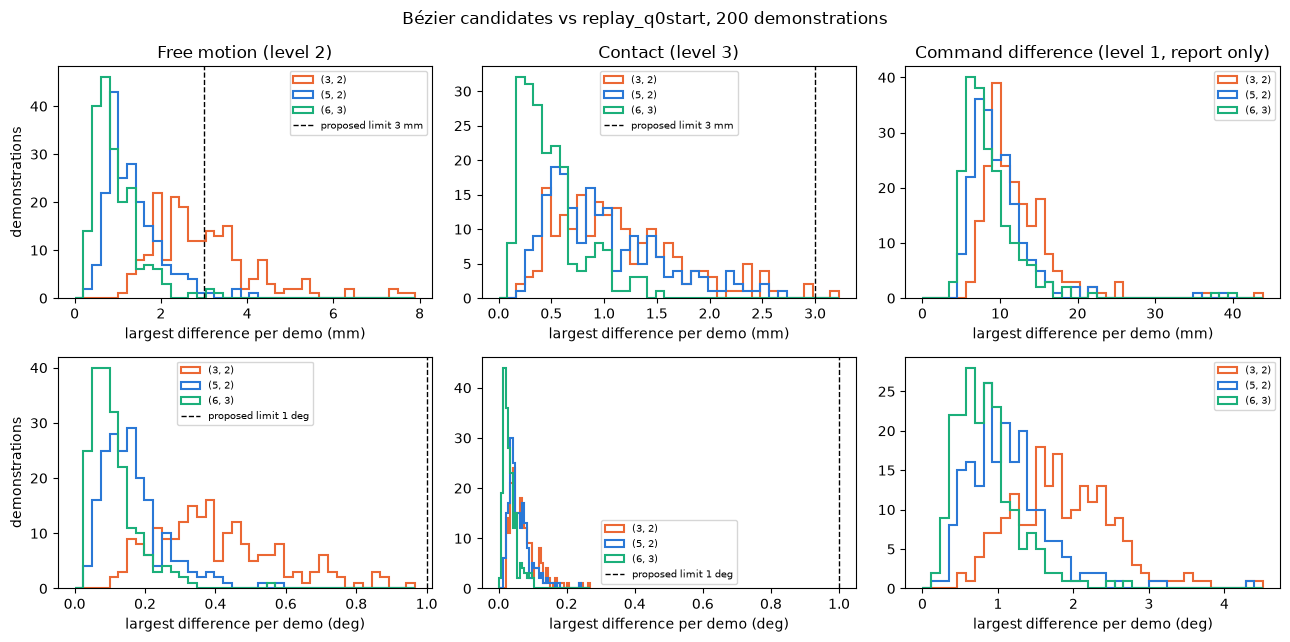

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
cfg_colors = dict(zip(CONFIGS, ("#eb6834", "#2a78d6", "#1baf7a")))
columns = (("free", "Free motion (level 2)"), ("contact", "Contact (level 3)"), ("cmd", "Command difference (level 1, report only)"))
for j, (key, title) in enumerate(columns):
    for i, (unit, scale, suffix, limit) in enumerate((("mm", 1000.0, "pos_max_m", 3.0), ("deg", np.degrees(1.0), "rot_max_rad", 1.0))):
        ax = axs[i, j]
        values = {cfg: np.array([x[f"{key}_{suffix}"] for x in RESULTS[cfg].values()]) * scale for cfg in CONFIGS}
        bins = np.linspace(0, max(v.max() for v in values.values()) * 1.02, 40)
        for cfg, v in values.items():
            ax.hist(v, bins=bins, histtype="step", lw=1.5, color=cfg_colors[cfg], label=f"{cfg}")
        if key != "cmd":
            ax.axvline(limit, color="black", ls="--", lw=1, label=f"proposed limit {limit:g} {unit}")
        ax.set(xlabel=f"largest difference per demo ({unit})", ylabel="demonstrations" if j == 0 else None, title=title if i == 0 else None)
        ax.legend(fontsize=7)
fig.suptitle("Bézier candidates vs replay_q0start, 200 demonstrations")
fig.tight_layout()
plt.show()

## 3.4 Videos

`scripts/render_side_by_side.py` replays the reference and the three candidates of one demonstration with a glfw renderer, and writes one mp4 with four panels. The files are in `docs/bezier-fit/videos/`:
- `demo_0_side_by_side.mp4`
- `demo_55_side_by_side.mp4`

## 3.5 Result of H24

**H24 is confirmed for all three candidates.** All four gate checks pass in every demonstration:
1. All 600 fits converge in one chart, with no active rotation bound, and $q_0$, $q_K$ are exact (largest end error 5e-16).
2. Command fidelity is exactly 0.
3. The close step equals the reference in every demonstration.
4. Every candidate lifts the cube in the same 199 demonstrations as `replay_q0start`. `demo_177` fails in the reference and in all three candidates.

**Fit residuals (reported only).** The median per-demo RMS position residual is 4.7, 3.9 and 3.3 mm for (3, 2), (5, 2) and (6, 3). The worst per-demo maximum is about 40 mm for all three: these are the single large command jumps of section 5.2 of the baseline notebook. The worst rotation maximum is 4.4°, 4.3° and 2.7°. This is much smaller than the 16° of the section 5.6 preview, because $q_0$ is now fixed at the start pose and the first-command spike is not in the target.

**Flags (proposed 3 mm / 1° limits, not fails):**

| (K1, K2) | level 2 (free motion) | level 3 (contact) |
| --- | --- | --- |
| (3, 2) | 84 demos, 3.0 to 7.7 mm, all below 1° | 1 demo (`demo_107`, 3.16 mm) |
| (5, 2) | 4 demos, 3.0 to 4.2 mm (`demo_84`, `demo_100`, `demo_107`, `demo_125`) | 0 |
| (6, 3) | 3 demos, 3.1 to 3.3 mm (`demo_84`, `demo_100`, `demo_107`) | 0 |

Inspection of the flags:
- For (5, 2) and (6, 3), every flagged maximum is at action 1 or 2, in the start transient. In these demonstrations the first commands jump: the command difference there is 16 to 40 mm. The curve starts at the fixed $q_0$ and does not follow this jump, so the gripper moves differently for the first 0.1 s. After that, the difference stays below 3 mm.
- For (3, 2), the flagged maxima are also early in the approach (median at 9 % of the approach, quartiles 7 % and 19 %). But with only 3 segments before the close command, the curve is also further from the commands later in the approach, so many more demonstrations go over 3 mm.
- No flag is in the rotation, and the contact differences stay at or below 3.2 mm in every candidate. The final cube heights differ by at most 5.3 mm.
- `demo_55` with (3, 2) has the largest cube difference (13.8 mm), with a contact difference of only 2.5 mm. It still lifts the cube. This agrees with the baseline finding that small differences in contact can grow.

**Interpretation.** All three candidates reproduce the task by the gate. (3, 2) is the coarsest: its free-motion differences pass 3 mm in 42 % of the demonstrations. (5, 2) and (6, 3) stay inside the proposed limits except in the start transient of a few demonstrations with a first-command jump.

**Videos:** in `docs/bezier-fit/videos/`, `demo_0` and `demo_55` show the reference and the three candidates side by side. All four lift the cube in both demonstrations.